# Cowrie Shell Dice: 
### Rules
"Down" if turtle-shell side up
"Up" if mouth of shell is up

Rolling the Cowrie Shells

Each up shell denotes 1 point.
Each downshell denotes 0 points.
If all 6 cowries are down, then it’s a full 12 points.
Possible scores: 1, 2, 3, 4, 5, 6, 12.


* Randomly placing the shell images on the canvas
* Must have distance between each other (roughly 2*radius of shells) so they don't overlap
* Must have some margin from the border so they don't get cut off

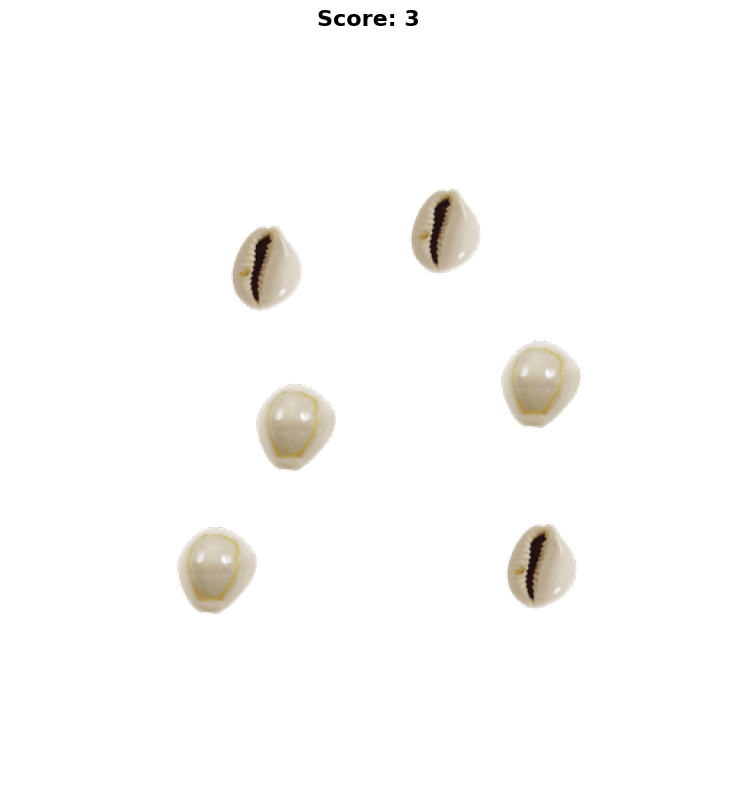

In [52]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from PIL import Image
import random
import math

CANVAS_WIDTH = 500
CANVAS_HEIGHT = 500
NUM_SHELLS = 6
SHELL_RADIUS = 50
MIN_DISTANCE = 110
MARGIN = 60

def calculate_distance(x1, y1, x2, y2):
    return math.sqrt((x2 - x1)**2 + (y2 - y1)**2)

def can_place_shell(x, y, existing_shells, min_distance):
    for shell_x, shell_y in existing_shells:
        if calculate_distance(x, y, shell_x, shell_y) < min_distance:
            return False
    return True

def generate_positions(num_shells, canvas_width, canvas_height, shell_radius, min_distance):
    positions = []
    for _ in range(num_shells):
        placed = False
        while not placed:
            x = random.randint(MARGIN + shell_radius, canvas_width - MARGIN - shell_radius)
            y = random.randint(MARGIN + shell_radius, canvas_height - MARGIN - shell_radius)
            if can_place_shell(x, y, positions, min_distance):
                positions.append((x, y))
                placed = True
    return positions

def roll_shells(num_shells):
    return [random.choice([0, 1]) for _ in range(num_shells)]

def calculate_score(states):
    up_count = sum(states)
    return 12 if up_count == 0 else up_count

def display_dice():
    states = roll_shells(NUM_SHELLS)
    positions = generate_positions(NUM_SHELLS, CANVAS_WIDTH, CANVAS_HEIGHT, SHELL_RADIUS, MIN_DISTANCE)
    score = calculate_score(states)
    
    cowrie_up_img = Image.open("../dice_images/cowrieup.png")
    cowrie_down_img = Image.open("../dice_images/cowriedown.png")
    cowrie_up_img = cowrie_up_img.resize((SHELL_RADIUS * 2, SHELL_RADIUS * 2))
    cowrie_down_img = cowrie_down_img.resize((SHELL_RADIUS * 2, SHELL_RADIUS * 2))
    
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_xlim(0, CANVAS_WIDTH)
    ax.set_ylim(CANVAS_HEIGHT, 0)
    ax.set_aspect('equal')
    ax.axis('off')
    
    for i, (x, y) in enumerate(positions):
        image = cowrie_up_img if states[i] == 1 else cowrie_down_img
        ax.imshow(image, extent=[x - SHELL_RADIUS, x + SHELL_RADIUS, y + SHELL_RADIUS, y - SHELL_RADIUS])
    
    ax.text(CANVAS_WIDTH // 2, -30, f"Score: {score}", ha='center', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

display_dice()

* Randomise rotation about the axis so it looks more realistic
* Animating the throw

In [30]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from PIL import Image
from IPython.display import HTML
import random
import math

CANVAS_WIDTH = 500
CANVAS_HEIGHT = 500
NUM_SHELLS = 6
SHELL_RADIUS = 50
MIN_DISTANCE = 110
MARGIN = 60

THROW_X = CANVAS_WIDTH / 2
THROW_Y = CANVAS_HEIGHT / 2
ANIMATION_FRAMES = 36
SETTLE_FRAMES = 8

def calculate_distance(x1, y1, x2, y2):
    return math.sqrt((x2 - x1)**2 + (y2 - y1)**2)

def can_place_shell(x, y, existing_shells, min_distance):
    for shell_x, shell_y in existing_shells:
        if calculate_distance(x, y, shell_x, shell_y) < min_distance:
            return False
    return True

def generate_positions(num_shells, canvas_width, canvas_height, shell_radius, min_distance):
    positions = []
    for _ in range(num_shells):
        placed = False
        while not placed:
            x = random.randint(MARGIN + shell_radius, canvas_width - MARGIN - shell_radius)
            y = random.randint(MARGIN + shell_radius, canvas_height - MARGIN - shell_radius)
            if can_place_shell(x, y, positions, min_distance):
                positions.append((x, y))
                placed = True
    return positions

def roll_shells(num_shells):
    return [random.choice([0, 1]) for _ in range(num_shells)]

def calculate_score(states):
    up_count = sum(states)
    return 12 if up_count == 0 else up_count

def smooth_step(value):
    value = max(0, min(1, value))
    return value * value * (3 - 2 * value)

def display_dice():
    states = roll_shells(NUM_SHELLS)
    final_positions = generate_positions(NUM_SHELLS, CANVAS_WIDTH, CANVAS_HEIGHT, SHELL_RADIUS, MIN_DISTANCE)
    final_angles = [random.randint(0, 359) for _ in range(NUM_SHELLS)]
    start_positions = [
        (THROW_X + random.uniform(-16, 16), THROW_Y + random.uniform(-16, 16))
        for _ in range(NUM_SHELLS)
    ]
    arc_heights = [random.uniform(28, 78) for _ in range(NUM_SHELLS)]
    spin_directions = [random.choice([-1, 1]) for _ in range(NUM_SHELLS)]
    score = calculate_score(states)
    
    cowrie_up_img = Image.open("../dice_images/cowrieup.png")
    cowrie_down_img = Image.open("../dice_images/cowriedown.png")
    cowrie_up_img = cowrie_up_img.resize((SHELL_RADIUS * 2, SHELL_RADIUS * 2))
    cowrie_down_img = cowrie_down_img.resize((SHELL_RADIUS * 2, SHELL_RADIUS * 2))
    
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_xlim(0, CANVAS_WIDTH)
    ax.set_ylim(CANVAS_HEIGHT, 0)
    ax.set_aspect('equal')
    ax.axis('off')
    
    shell_artists = []
    for _ in range(NUM_SHELLS):
        artist = ax.imshow(cowrie_up_img, extent=[0, 0, 0, 0], animated=True)
        shell_artists.append(artist)
    
    def build_frame(frame_index):
        ax.set_title(f"Score: {score}", fontsize=16, fontweight='bold', pad=14)
        progress = smooth_step(frame_index / max(1, ANIMATION_FRAMES - 1))
        toss_wave = math.sin(progress * math.pi * 4)
        spin_decay = 1 - progress
        
        for shell_index, artist in enumerate(shell_artists):
            start_x, start_y = start_positions[shell_index]
            end_x, end_y = final_positions[shell_index]
            arc_height = arc_heights[shell_index] * math.sin(progress * math.pi)
            travel_x = start_x + (end_x - start_x) * progress
            travel_y = start_y + (end_y - start_y) * progress - arc_height * (1 - progress)
            travel_y += toss_wave * 4 * spin_decay
            
            image = cowrie_up_img if states[shell_index] == 1 else cowrie_down_img
            current_angle = (
                spin_directions[shell_index] * (900 * spin_decay)
                + final_angles[shell_index] * progress
            )
            if progress >= 0.95:
                current_angle = final_angles[shell_index]
                travel_x = end_x
                travel_y = end_y
            rotated_image = image.rotate(current_angle, resample=Image.BICUBIC)
            artist.set_data(rotated_image)
            artist.set_extent([
                travel_x - SHELL_RADIUS,
                travel_x + SHELL_RADIUS,
                travel_y + SHELL_RADIUS,
                travel_y - SHELL_RADIUS,
            ])
        return shell_artists
    
    animation = FuncAnimation(
        fig,
        build_frame,
        frames=ANIMATION_FRAMES,
        interval=45,
        blit=False,
        repeat=False,
    )
    
    plt.close(fig)
    return HTML(animation.to_jshtml())


display_dice()

A good start but the motion seems largely lateral (right to left) and spinning, which isn't quite how these shells move

In [44]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from PIL import Image
from IPython.display import HTML
import random
import math

CANVAS_WIDTH = 500
CANVAS_HEIGHT = 500
NUM_SHELLS = 6
SHELL_RADIUS = 50
MIN_DISTANCE = 110 # between shells
MARGIN = 60

# start throw at centre of canvas
THROW_X = CANVAS_WIDTH / 2 
THROW_Y = CANVAS_HEIGHT / 2

ANIMATION_FRAMES = 36
SETTLE_FRAMES = 8 # final 8 frames are for settling into final position without movement

def calculate_distance(x1, y1, x2, y2):
    return math.sqrt((x2 - x1)**2 + (y2 - y1)**2)

# verifies that a shell can be placed at (x, y) without being too close to existing shells
def can_place_shell(x, y, existing_shells, min_distance):
    for shell_x, shell_y in existing_shells:
        if calculate_distance(x, y, shell_x, shell_y) < min_distance:
            return False
    return True

def generate_positions(num_shells, canvas_width, canvas_height, shell_radius, min_distance):
    positions = []
    for _ in range(num_shells):
        placed = False
        while not placed:
            x = random.randint(MARGIN + shell_radius, canvas_width - MARGIN - shell_radius)
            y = random.randint(MARGIN + shell_radius, canvas_height - MARGIN - shell_radius)
            if can_place_shell(x, y, positions, min_distance):
                positions.append((x, y))
                placed = True
    return positions

def roll_shells(num_shells):
    return [random.choice([0, 1]) for _ in range(num_shells)]

def calculate_score(states):
    up_count = sum(states)
    return 12 if up_count == 0 else up_count

def smooth_step(value):
    value = max(0, min(1, value))
    return value * value * (3 - 2 * value)

def display_dice():
    states = roll_shells(NUM_SHELLS)
    final_positions = generate_positions(NUM_SHELLS, CANVAS_WIDTH, CANVAS_HEIGHT, SHELL_RADIUS, MIN_DISTANCE)
    final_angles = [random.randint(0, 359) for _ in range(NUM_SHELLS)]
    start_positions = [
        (THROW_X + random.uniform(-16, 16), THROW_Y + random.uniform(-16, 16))
        for _ in range(NUM_SHELLS)
    ]
    arc_heights = [random.uniform(28, 78) for _ in range(NUM_SHELLS)]
    spin_directions = [random.choice([-1, 1]) for _ in range(NUM_SHELLS)]
    score = calculate_score(states)
    
    cowrie_up_img = Image.open("../dice_images/cowrieup.png")
    cowrie_down_img = Image.open("../dice_images/cowriedown.png")
    cowrie_up_img = cowrie_up_img.resize((SHELL_RADIUS * 2, SHELL_RADIUS * 2))
    cowrie_down_img = cowrie_down_img.resize((SHELL_RADIUS * 2, SHELL_RADIUS * 2))
    
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_xlim(0, CANVAS_WIDTH)
    ax.set_ylim(CANVAS_HEIGHT, 0)
    ax.set_aspect('equal')
    ax.axis('off')
    
    shell_artists = []
    for _ in range(NUM_SHELLS):
        artist = ax.imshow(cowrie_up_img, extent=[0, 0, 0, 0], animated=True)
        shell_artists.append(artist)
    
    def build_frame(frame_index):
        ax.set_title(f"Score: {score}", fontsize=16, fontweight='bold', pad=14)
        progress = smooth_step(frame_index / max(1, ANIMATION_FRAMES - 1))
        toss_wave = math.sin(progress * math.pi * 4)
        spin_decay = 1 - progress
        
        for shell_index, artist in enumerate(shell_artists):
            start_x, start_y = start_positions[shell_index]
            end_x, end_y = final_positions[shell_index]
            arc_height = arc_heights[shell_index] * math.sin(progress * math.pi)
            travel_x = start_x + (end_x - start_x) * progress
            travel_y = start_y + (end_y - start_y) * progress - arc_height * (1 - progress)
            travel_y += toss_wave * 4 * spin_decay
            
            image = cowrie_up_img if states[shell_index] == 1 else cowrie_down_img
            current_angle = (
                spin_directions[shell_index] * (900 * spin_decay)
                + final_angles[shell_index] * progress
            )
            if progress >= 0.95:
                current_angle = final_angles[shell_index]
                travel_x = end_x
                travel_y = end_y
            rotated_image = image.rotate(current_angle, resample=Image.BICUBIC)
            artist.set_data(rotated_image)
            artist.set_extent([
                travel_x - SHELL_RADIUS,
                travel_x + SHELL_RADIUS,
                travel_y + SHELL_RADIUS,
                travel_y - SHELL_RADIUS,
            ])
        return shell_artists
    
    animation = FuncAnimation(
        fig,
        build_frame,
        frames=ANIMATION_FRAMES,
        interval=45,
        blit=False,
        repeat=False,
    )
    
    plt.close(fig)
    return HTML(animation.to_jshtml())


display_dice()

* Starting the throw with all the shells facing up?
* These shells don't normally just fall, they also switch up their up/down until the last second
* Experimenting with chaos/heavier/faster tosses

In [43]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from PIL import Image
from IPython.display import HTML
import random
import math

CANVAS_WIDTH = 500
CANVAS_HEIGHT = 500
NUM_SHELLS = 6
SHELL_RADIUS = 50
MIN_DISTANCE = 110
MARGIN = 60

THROW_X = CANVAS_WIDTH / 2
THROW_Y = CANVAS_HEIGHT / 2
ANIMATION_FRAMES = 42

def calculate_distance(x1, y1, x2, y2):
    return math.sqrt((x2 - x1)**2 + (y2 - y1)**2)

def can_place_shell(x, y, existing_shells, min_distance):
    for shell_x, shell_y in existing_shells:
        if calculate_distance(x, y, shell_x, shell_y) < min_distance:
            return False
    return True

def generate_positions(num_shells, canvas_width, canvas_height, shell_radius, min_distance):
    positions = []
    for _ in range(num_shells):
        placed = False
        while not placed:
            x = random.randint(MARGIN + shell_radius, canvas_width - MARGIN - shell_radius)
            y = random.randint(MARGIN + shell_radius, canvas_height - MARGIN - shell_radius)
            if can_place_shell(x, y, positions, min_distance):
                positions.append((x, y))
                placed = True
    return positions

def roll_shells(num_shells):
    return [random.choice([0, 1]) for _ in range(num_shells)]

def calculate_score(states):
    up_count = sum(states)
    return 12 if up_count == 0 else up_count

def smooth_step(value):
    value = max(0, min(1, value))
    return value * value * (3 - 2 * value)

def display_dice():
    final_states = roll_shells(NUM_SHELLS)
    final_positions = generate_positions(NUM_SHELLS, CANVAS_WIDTH, CANVAS_HEIGHT, SHELL_RADIUS, MIN_DISTANCE)
    final_angles = [random.randint(0, 359) for _ in range(NUM_SHELLS)]
    score = calculate_score(final_states)

    cowrie_up_img = Image.open("../dice_images/cowrieup.png")
    cowrie_down_img = Image.open("../dice_images/cowriedown.png")
    cowrie_up_img = cowrie_up_img.resize((SHELL_RADIUS * 2, SHELL_RADIUS * 2))
    cowrie_down_img = cowrie_down_img.resize((SHELL_RADIUS * 2, SHELL_RADIUS * 2))

    start_positions = [
        (THROW_X + random.uniform(-12, 12), THROW_Y + random.uniform(-12, 12))
        for _ in range(NUM_SHELLS)
    ]
    flip_frames = [random.randint(8, 28) for _ in range(NUM_SHELLS)]
    settle_frames = [random.randint(30, 39) for _ in range(NUM_SHELLS)]
    arc_heights = [random.uniform(30, 85) for _ in range(NUM_SHELLS)]
    spin_directions = [random.choice([-1, 1]) for _ in range(NUM_SHELLS)]
    toss_noise = [random.uniform(0.5, 1.5) for _ in range(NUM_SHELLS)]

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_xlim(0, CANVAS_WIDTH)
    ax.set_ylim(CANVAS_HEIGHT, 0)
    ax.set_aspect('equal')
    ax.axis('off')

    shell_artists = []
    for _ in range(NUM_SHELLS):
        artist = ax.imshow(cowrie_up_img, extent=[0, 0, 0, 0], animated=True)
        shell_artists.append(artist)

    def shell_state_at_frame(shell_index, frame_index):
        if frame_index < flip_frames[shell_index]:
            return 1
        if frame_index < settle_frames[shell_index]:
            if random.random() < 0.28:
                return 1 - final_states[shell_index]
        return final_states[shell_index]

    def build_frame(frame_index):
        progress = smooth_step(frame_index / max(1, ANIMATION_FRAMES - 1))
        toss_wave = math.sin(progress * math.pi * 4)
        for shell_index, artist in enumerate(shell_artists):
            start_x, start_y = start_positions[shell_index]
            end_x, end_y = final_positions[shell_index]
            arc_height = arc_heights[shell_index] * math.sin(progress * math.pi)
            travel_x = start_x + (end_x - start_x) * progress
            travel_y = start_y + (end_y - start_y) * progress - arc_height * (1 - progress)
            travel_y += toss_noise[shell_index] * toss_wave * (1 - progress) * 4

            shell_state = shell_state_at_frame(shell_index, frame_index)
            image = cowrie_up_img if shell_state == 1 else cowrie_down_img
            current_angle = spin_directions[shell_index] * (960 * (1 - progress)) + final_angles[shell_index] * progress
            if progress >= 0.96:
                current_angle = final_angles[shell_index]
                travel_x = end_x
                travel_y = end_y

            rotated_image = image.rotate(current_angle, resample=Image.BICUBIC)
            artist.set_data(rotated_image)
            artist.set_extent([
                travel_x - SHELL_RADIUS,
                travel_x + SHELL_RADIUS,
                travel_y + SHELL_RADIUS,
                travel_y - SHELL_RADIUS,
            ])

        ax.set_title(f"Score: {score}", fontsize=16, fontweight='bold', pad=14)
        return shell_artists

    animation = FuncAnimation(
        fig,
        build_frame,
        frames=ANIMATION_FRAMES,
        interval=45,
        blit=False,
        repeat=False,
    )

    plt.close(fig)
    return HTML(animation.to_jshtml())

display_dice()

Adding the random flips from up to down as the throw progresses seems to improve the realism significantly! Experimenting now with its speed.

In [51]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from PIL import Image
from IPython.display import HTML
import random
import math

CANVAS_WIDTH = 500
CANVAS_HEIGHT = 500
NUM_SHELLS = 6
SHELL_RADIUS = 50
MIN_DISTANCE = 110
MARGIN = 60

THROW_X = CANVAS_WIDTH / 2
THROW_Y = CANVAS_HEIGHT / 2
ANIMATION_FRAMES = 42

def calculate_distance(x1, y1, x2, y2):
    return math.sqrt((x2 - x1)**2 + (y2 - y1)**2)

def can_place_shell(x, y, existing_shells, min_distance):
    for shell_x, shell_y in existing_shells:
        if calculate_distance(x, y, shell_x, shell_y) < min_distance:
            return False
    return True

def generate_positions(num_shells, canvas_width, canvas_height, shell_radius, min_distance):
    positions = []
    for _ in range(num_shells):
        placed = False
        while not placed:
            x = random.randint(MARGIN + shell_radius, canvas_width - MARGIN - shell_radius)
            y = random.randint(MARGIN + shell_radius, canvas_height - MARGIN - shell_radius)
            if can_place_shell(x, y, positions, min_distance):
                positions.append((x, y))
                placed = True
    return positions

def roll_shells(num_shells):
    return [random.choice([0, 1]) for _ in range(num_shells)]

def calculate_score(states):
    up_count = sum(states)
    return 12 if up_count == 0 else up_count

def smooth_step(value):
    value = max(0, min(1, value))
    return value * value * (3 - 2 * value)

def display_dice():
    final_states = roll_shells(NUM_SHELLS)
    final_positions = generate_positions(NUM_SHELLS, CANVAS_WIDTH, CANVAS_HEIGHT, SHELL_RADIUS, MIN_DISTANCE)
    final_angles = [random.randint(0, 359) for _ in range(NUM_SHELLS)]
    score = calculate_score(final_states)

    cowrie_up_img = Image.open("../dice_images/cowrieup.png")
    cowrie_down_img = Image.open("../dice_images/cowriedown.png")
    cowrie_up_img = cowrie_up_img.resize((SHELL_RADIUS * 2, SHELL_RADIUS * 2))
    cowrie_down_img = cowrie_down_img.resize((SHELL_RADIUS * 2, SHELL_RADIUS * 2))

    start_positions = [
        (THROW_X + random.uniform(-12, 12), THROW_Y + random.uniform(-12, 12))
        for _ in range(NUM_SHELLS)
    ]
    flip_frames = [random.randint(8, 28) for _ in range(NUM_SHELLS)]
    settle_frames = [random.randint(30, 39) for _ in range(NUM_SHELLS)]
    arc_heights = [random.uniform(30, 85) for _ in range(NUM_SHELLS)]
    spin_directions = [random.choice([-1, 1]) for _ in range(NUM_SHELLS)]
    toss_noise = [random.uniform(0.5, 1.5) for _ in range(NUM_SHELLS)]

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_xlim(0, CANVAS_WIDTH)
    ax.set_ylim(CANVAS_HEIGHT, 0)
    ax.set_aspect('equal')
    ax.axis('off')

    shell_artists = []
    for _ in range(NUM_SHELLS):
        artist = ax.imshow(cowrie_up_img, extent=[0, 0, 0, 0], animated=True)
        shell_artists.append(artist)

    def shell_state_at_frame(shell_index, frame_index):
        if frame_index < flip_frames[shell_index]:
            return 1
        if frame_index < settle_frames[shell_index]:
            if random.random() < 0.28:
                return 1 - final_states[shell_index]
        return final_states[shell_index]

    def build_frame(frame_index):
        progress = smooth_step(frame_index / max(1, ANIMATION_FRAMES - 1))
        toss_wave = math.sin(progress * math.pi * 4)
        for shell_index, artist in enumerate(shell_artists):
            start_x, start_y = start_positions[shell_index]
            end_x, end_y = final_positions[shell_index]
            arc_height = arc_heights[shell_index] * math.sin(progress * math.pi)
            travel_x = start_x + (end_x - start_x) * progress
            travel_y = start_y + (end_y - start_y) * progress - arc_height * (1 - progress)
            travel_y += toss_noise[shell_index] * toss_wave * (1 - progress) * 4

            shell_state = shell_state_at_frame(shell_index, frame_index)
            image = cowrie_up_img if shell_state == 1 else cowrie_down_img
            current_angle = spin_directions[shell_index] * (960 * (1 - progress)) + final_angles[shell_index] * progress
            if progress >= 0.96:
                current_angle = final_angles[shell_index]
                travel_x = end_x
                travel_y = end_y

            rotated_image = image.rotate(current_angle, resample=Image.BICUBIC)
            artist.set_data(rotated_image)
            artist.set_extent([
                travel_x - SHELL_RADIUS,
                travel_x + SHELL_RADIUS,
                travel_y + SHELL_RADIUS,
                travel_y - SHELL_RADIUS,
            ])

        ax.set_title(f"Score: {score}", fontsize=16, fontweight='bold', pad=14)
        return shell_artists

    animation = FuncAnimation(
        fig,
        build_frame,
        frames=ANIMATION_FRAMES,
        interval=45,
        blit=False,
        repeat=False,
    )

    plt.close(fig)
    return HTML(animation.to_jshtml())

display_dice()

This is the final version^

--------------------------------------------------------------------------------------

## Other experiments:

This section is not used in the final project:

In [50]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from PIL import Image
from IPython.display import HTML
import random
import math

CANVAS_WIDTH = 500
CANVAS_HEIGHT = 500
NUM_SHELLS = 6
SHELL_RADIUS = 50
MIN_DISTANCE = 110
MARGIN = 60

THROW_X = CANVAS_WIDTH / 2
THROW_Y = CANVAS_HEIGHT / 2
ANIMATION_FRAMES = 30

def calculate_distance(x1, y1, x2, y2):
    return math.sqrt((x2 - x1)**2 + (y2 - y1)**2)

def can_place_shell(x, y, existing_shells, min_distance):
    for shell_x, shell_y in existing_shells:
        if calculate_distance(x, y, shell_x, shell_y) < min_distance:
            return False
    return True

def generate_positions(num_shells, canvas_width, canvas_height, shell_radius, min_distance):
    positions = []
    for _ in range(num_shells):
        placed = False
        while not placed:
            x = random.randint(MARGIN + shell_radius, canvas_width - MARGIN - shell_radius)
            y = random.randint(MARGIN + shell_radius, canvas_height - MARGIN - shell_radius)
            if can_place_shell(x, y, positions, min_distance):
                positions.append((x, y))
                placed = True
    return positions

def roll_shells(num_shells):
    return [random.choice([0, 1]) for _ in range(num_shells)]

def calculate_score(states):
    up_count = sum(states)
    return 12 if up_count == 0 else up_count

def smooth_step(value):
    value = max(0, min(1, value))
    return value * value * (3 - 2 * value)

def display_dice():
    final_states = roll_shells(NUM_SHELLS)
    final_positions = generate_positions(NUM_SHELLS, CANVAS_WIDTH, CANVAS_HEIGHT, SHELL_RADIUS, MIN_DISTANCE)
    final_angles = [random.randint(0, 359) for _ in range(NUM_SHELLS)]
    score = calculate_score(final_states)

    cowrie_up_img = Image.open("../dice_images/cowrieup.png")
    cowrie_down_img = Image.open("../dice_images/cowriedown.png")
    cowrie_up_img = cowrie_up_img.resize((SHELL_RADIUS * 2, SHELL_RADIUS * 2))
    cowrie_down_img = cowrie_down_img.resize((SHELL_RADIUS * 2, SHELL_RADIUS * 2))

    start_positions = [
        (THROW_X + random.uniform(-12, 12), THROW_Y + random.uniform(-12, 12))
        for _ in range(NUM_SHELLS)
    ]
    flip_frames = [random.randint(5, 18) for _ in range(NUM_SHELLS)]
    settle_frames = [random.randint(20, 27) for _ in range(NUM_SHELLS)]
    arc_heights = [random.uniform(24, 62) for _ in range(NUM_SHELLS)]
    spin_directions = [random.choice([-1, 1]) for _ in range(NUM_SHELLS)]
    toss_noise = [random.uniform(0.4, 1.1) for _ in range(NUM_SHELLS)]

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_xlim(0, CANVAS_WIDTH)
    ax.set_ylim(CANVAS_HEIGHT, 0)
    ax.set_aspect('equal')
    ax.axis('off')

    shell_artists = []
    for _ in range(NUM_SHELLS):
        artist = ax.imshow(cowrie_up_img, extent=[0, 0, 0, 0], animated=True)
        shell_artists.append(artist)

    settled_states = [1] * NUM_SHELLS
    flip_chances = [random.uniform(0.16, 0.34) for _ in range(NUM_SHELLS)]

    def shell_state_at_frame(shell_index, frame_index):
        if frame_index < flip_frames[shell_index]:
            return 1
        if frame_index < settle_frames[shell_index]:
            if random.random() < flip_chances[shell_index]:
                return 1 - settled_states[shell_index]
        else:
            settled_states[shell_index] = final_states[shell_index]
        return settled_states[shell_index]

    def build_frame(frame_index):
        ax.set_title(f"Score: {score}", fontsize=16, fontweight='bold', pad=14)
        progress = smooth_step(frame_index / max(1, ANIMATION_FRAMES - 1))
        toss_wave = math.sin(progress * math.pi * 4)
        for shell_index, artist in enumerate(shell_artists):
            start_x, start_y = start_positions[shell_index]
            end_x, end_y = final_positions[shell_index]
            arc_height = arc_heights[shell_index] * math.sin(progress * math.pi)
            travel_x = start_x + (end_x - start_x) * progress
            travel_y = start_y + (end_y - start_y) * progress - arc_height * (1 - progress)
            travel_y += toss_noise[shell_index] * toss_wave * (1 - progress) * 4

            shell_state = shell_state_at_frame(shell_index, frame_index)
            image = cowrie_up_img if shell_state == 1 else cowrie_down_img
            current_angle = spin_directions[shell_index] * (960 * (1 - progress)) + final_angles[shell_index] * progress
            if progress >= 0.96:
                current_angle = final_angles[shell_index]
                travel_x = end_x
                travel_y = end_y

            rotated_image = image.rotate(current_angle, resample=Image.BICUBIC)
            artist.set_data(rotated_image)
            artist.set_extent([
                travel_x - SHELL_RADIUS,
                travel_x + SHELL_RADIUS,
                travel_y + SHELL_RADIUS,
                travel_y - SHELL_RADIUS,
            ])
        return shell_artists

    animation = FuncAnimation(
        fig,
        build_frame,
        frames=ANIMATION_FRAMES,
        interval=30,
        blit=False,
        repeat=False,
    )

    plt.close(fig)
    return HTML(animation.to_jshtml())


display_dice()

Rotational speed is more visible than movement.
I'm actually a bit happier with the previous speed and code, so using that!

-------------